## 1. Chuẩn bị ảnh và hàm hiển thị

In [11]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Notebook chạy được khi mở từ thư mục CV hoặc ngay trong lab4.
if Path("lab4/RBC1.jpg").exists():
    LAB_DIR = Path("lab4")
else:
    LAB_DIR = Path(".")

def read_gray(filename):
    """Đọc ảnh xám và báo lỗi nếu không tìm thấy ảnh."""
    path = LAB_DIR / filename
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f"Không đọc được ảnh: {path}")
    return image

def show_images(images, titles, cols=4, figsize=None):
    """Hiển thị nhiều ảnh theo lưới, phù hợp để so sánh trước/sau."""
    rows = (len(images) + cols - 1) // cols
    if figsize is None:
        figsize = (4 * cols, 3.5 * rows)
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, image, title in zip(axes.ravel(), images, titles):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    for ax in axes.ravel()[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def make_binary(image, invert=True):
    """Dùng Otsu; invert=True khi tế bào tối trên nền sáng."""
    mode = cv2.THRESH_BINARY_INV if invert else cv2.THRESH_BINARY
    _, binary = cv2.threshold(image, 0, 255, mode + cv2.THRESH_OTSU)
    return binary

def foreground_area(binary):
    """Diện tích foreground trắng, tính theo pixel."""
    return int(np.count_nonzero(binary))

def component_count(binary):
    """Số vùng trắng liên thông, bỏ nhãn nền."""
    count, _ = cv2.connectedComponents((binary > 0).astype(np.uint8))
    return count - 1

def hole_count(binary):
    """Đếm vùng đen kín nằm bên trong foreground trắng."""
    background = (binary == 0).astype(np.uint8)
    count, labels = cv2.connectedComponents(background)
    outside_label = labels[0, 0]
    labels_inside = set(np.unique(labels)) - {0, outside_label}
    return len(labels_inside)


Chọn ảnh đầu vào. Ảnh RBC/WBC là ảnh xám; khi tạo mask, `invert=True` giả định tế bào tối hơn nền. Nếu mask nền trắng và tế bào đen, đổi thành `invert=False`.

RBC1.jpg (800, 1000) uint8
RBC2.jpg (898, 910) uint8
RBC3.jpg (768, 1024) uint8
WBC1.jpg (420, 585) uint8
WBC2.jpg (459, 612) uint8


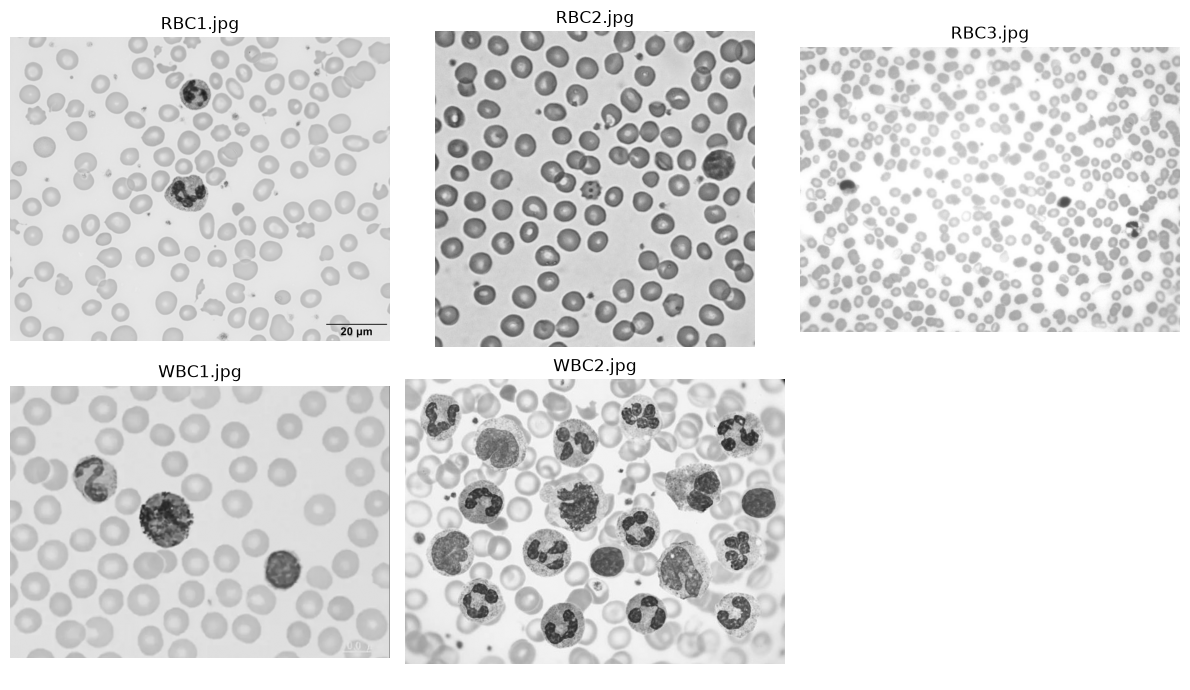

In [12]:
image_names = ["RBC1.jpg", "RBC2.jpg", "RBC3.jpg", "WBC1.jpg", "WBC2.jpg"]
images = {name: read_gray(name) for name in image_names}

for name, image in images.items():
    print(name, image.shape, image.dtype)

show_images(list(images.values()), image_names, cols=3)


Tạo mask cho một ảnh để dùng thống nhất ở các phép toán tiếp theo.

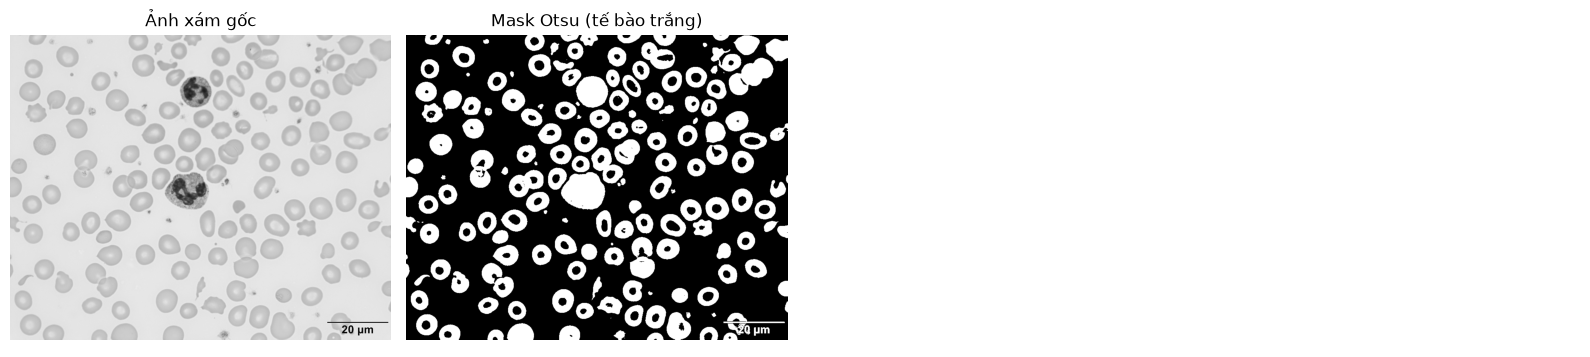

In [13]:
image = images["RBC1.jpg"]
binary = make_binary(image, invert=True)
show_images([image, binary], ["Ảnh xám gốc", "Mask Otsu (tế bào trắng)"])


## 2. Kernel / structuring element

Square 5x5:
 [[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
Ellipse 5x5:
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]
Cross 5x5:
 [[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]


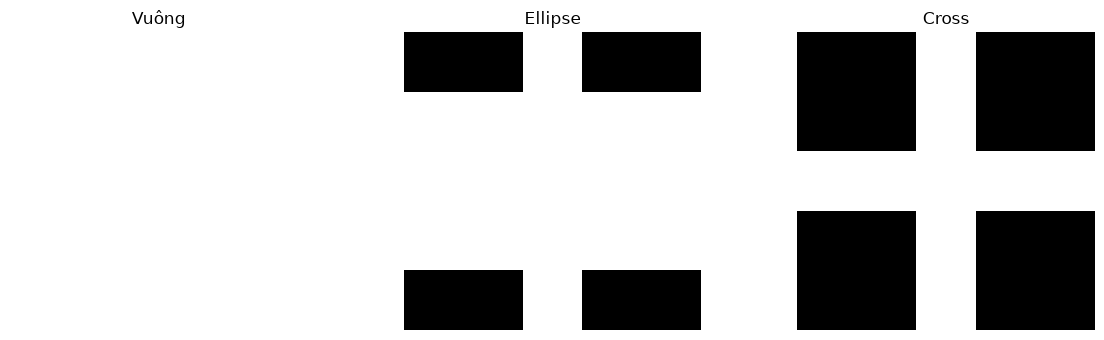

In [14]:
# Ba kernel thường dùng. Giá trị 1 là phần tử tham gia phép toán.
kernel_square = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
kernel_ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
kernel_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5))

print("Square 5x5:\n", kernel_square)
print("Ellipse 5x5:\n", kernel_ellipse)
print("Cross 5x5:\n", kernel_cross)
show_images(
    [kernel_square * 255, kernel_ellipse * 255, kernel_cross * 255],
    ["Vuông", "Ellipse", "Cross"],
    cols=3,
)


## 3. Tự cài đặt co và giãn ảnh xám bằng NumPy

Co lấy giá trị nhỏ nhất trong cửa sổ; giãn lấy giá trị lớn nhất. Cài đặt vòng lặp giúp thấy rõ quy tắc, còn OpenCV phù hợp khi cần chạy nhanh.

In [15]:
def grayscale_erosion_numpy(image, ksize=3):
    pad = ksize // 2
    padded = np.pad(image, pad, mode="edge")
    result = np.zeros_like(image)

    for y in range(image.shape[0]):
        for x in range(image.shape[1]):
            window = padded[y:y + ksize, x:x + ksize]
            result[y, x] = np.min(window)

    return result

def grayscale_dilation_numpy(image, ksize=3):
    pad = ksize // 2
    padded = np.pad(image, pad, mode="edge")
    result = np.zeros_like(image)

    for y in range(image.shape[0]):
        for x in range(image.shape[1]):
            window = padded[y:y + ksize, x:x + ksize]
            result[y, x] = np.max(window)

    return result


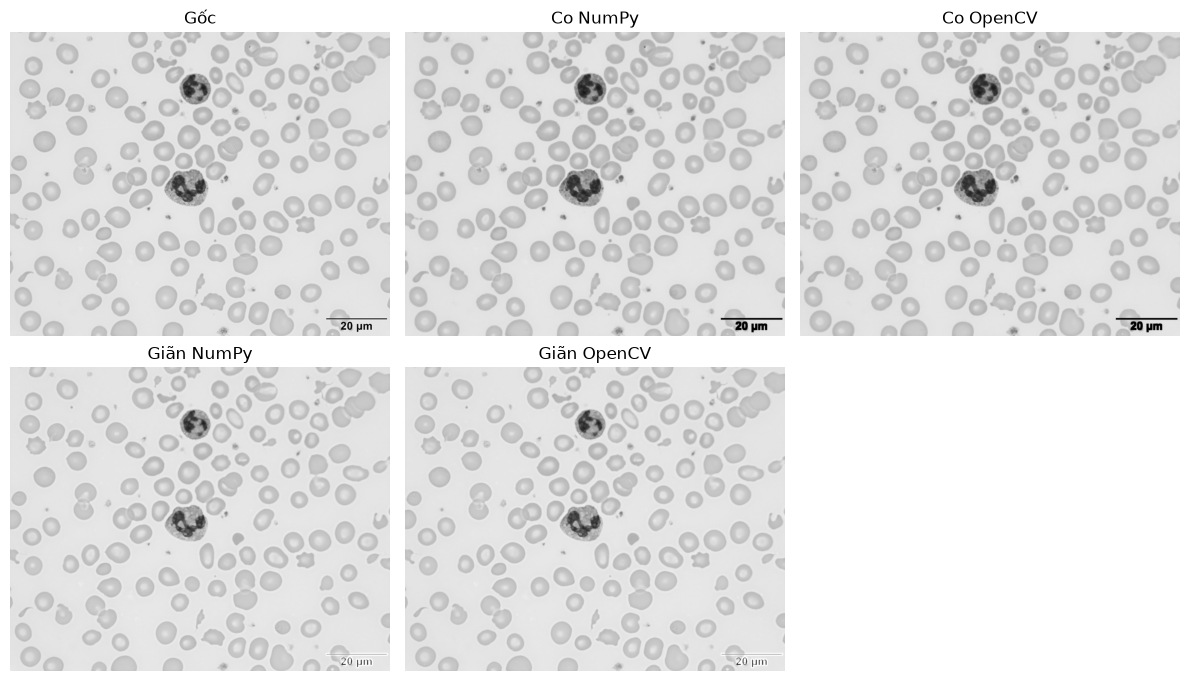

In [16]:
# So sánh code NumPy với OpenCV trên cùng ảnh xám.
eroded_numpy = grayscale_erosion_numpy(image, ksize=3)
dilated_numpy = grayscale_dilation_numpy(image, ksize=3)
kernel3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
eroded_cv = cv2.erode(image, kernel3, iterations=1)
dilated_cv = cv2.dilate(image, kernel3, iterations=1)

show_images(
    [image, eroded_numpy, eroded_cv, dilated_numpy, dilated_cv],
    ["Gốc", "Co NumPy", "Co OpenCV", "Giãn NumPy", "Giãn OpenCV"],
    cols=3,
)


## 4. Co (erosion) trên ảnh xám và ảnh nhị phân

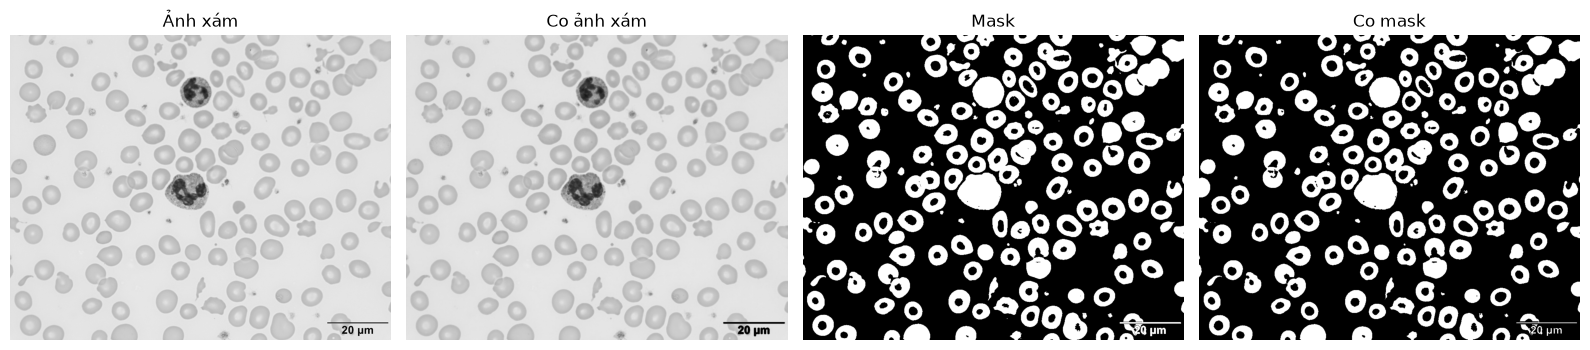

In [17]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
eroded_gray = cv2.erode(image, kernel, iterations=1)
eroded_binary = cv2.erode(binary, kernel, iterations=1)

show_images(
    [image, eroded_gray, binary, eroded_binary],
    ["Ảnh xám", "Co ảnh xám", "Mask", "Co mask"],
)


### Bài mở rộng Co 1 — kernel 3×3, 5×5, 7×7

So sánh diện tích foreground sau co. Với ảnh tế bào thật, diện tích đếm được phụ thuộc mask Otsu; khi so sánh, giữ nguyên ảnh và chỉ đổi kernel.

Kernel 3x3: area = 223958 pixels
Kernel 5x5: area = 190215 pixels
Kernel 7x7: area = 164734 pixels


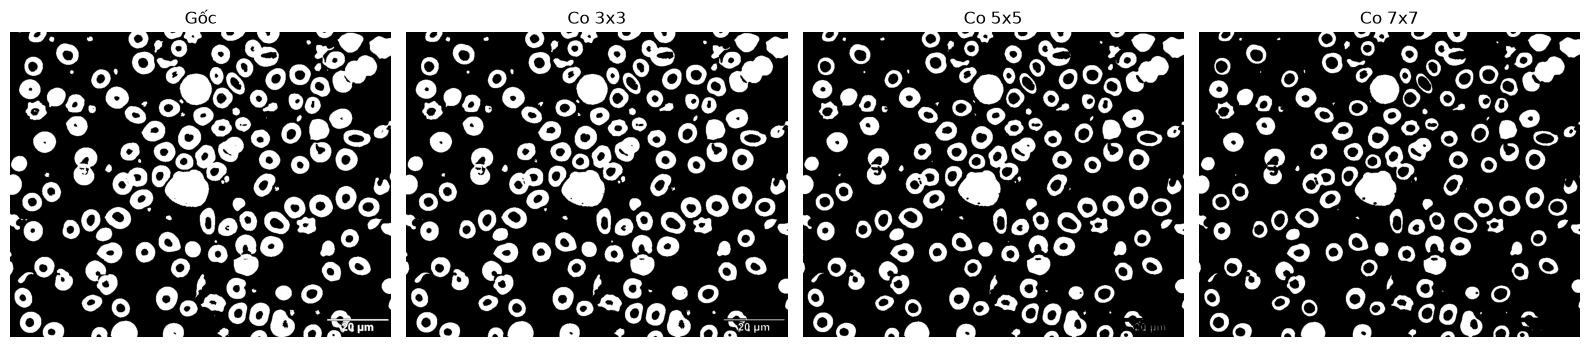

In [18]:
erosion_results = []
for size in (3, 5, 7):
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    result = cv2.erode(binary, kernel, iterations=1)
    erosion_results.append(result)
    print(f"Kernel {size}x{size}: area = {foreground_area(result)} pixels")

show_images(
    [binary] + erosion_results,
    ["Gốc", "Co 3x3", "Co 5x5", "Co 7x7"],
)


### Nhận xét — ảnh hưởng kích thước kernel khi co

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


### Bài mở rộng Co 2 — kernel vuông và ellipse

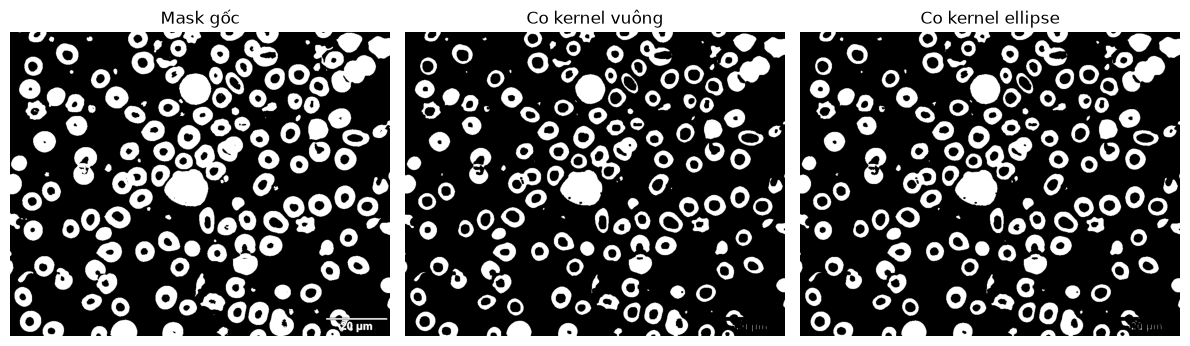

In [19]:
square3 = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
ellipse3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
eroded_square = cv2.erode(binary, square3, iterations=1)
eroded_ellipse = cv2.erode(binary, ellipse3, iterations=1)

show_images(
    [binary, eroded_square, eroded_ellipse],
    ["Mask gốc", "Co kernel vuông", "Co kernel ellipse"],
    cols=3,
)


### Nhận xét — vuông và ellipse trên tế bào

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


### Bài mở rộng Co 3 — tăng iterations để thử tách các tế bào gần nhau

Cell thử erosion 1–4 lần trên các ảnh hồng cầu; ghi số thành phần và diện tích để thấy lúc nào cầu nối mảnh bị tách. Nếu ảnh đã có mask phù hợp hơn, đổi `binary` sang mask đó.

RBC1.jpg
  iterations=1: components=177, area=213155
  iterations=2: components=180, area=176455
  iterations=3: components=166, area=141314
  iterations=4: components=183, area=107433


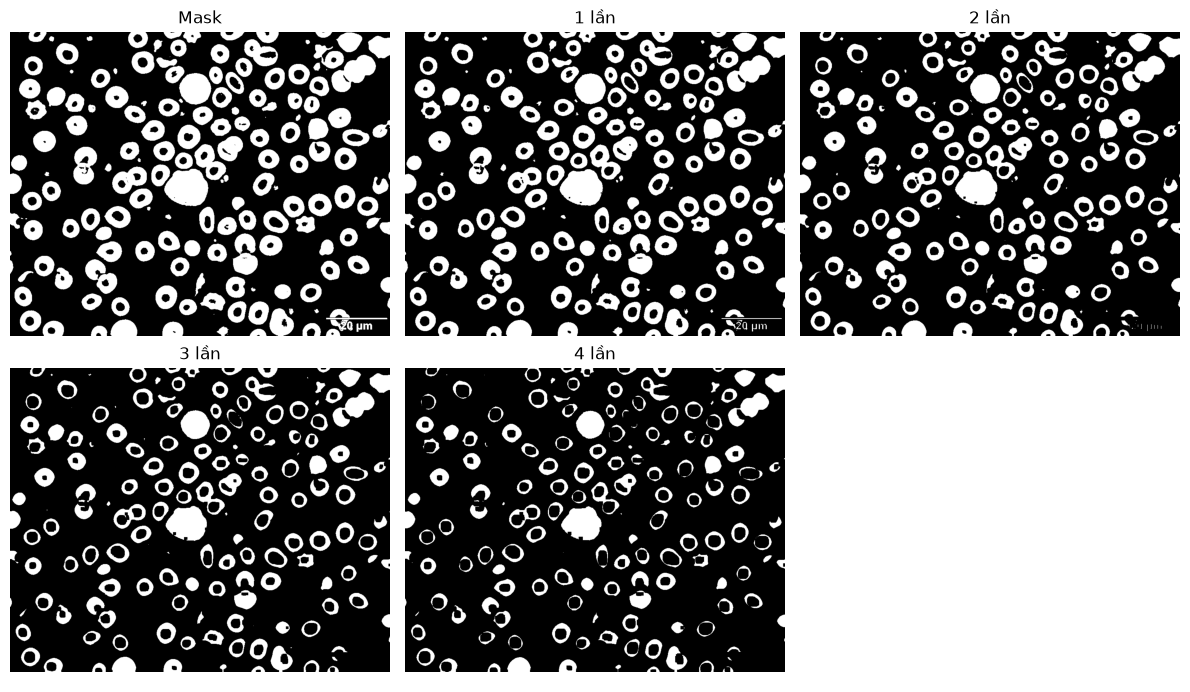

RBC2.jpg
  iterations=1: components=122, area=257952
  iterations=2: components=120, area=226286
  iterations=3: components=118, area=195057
  iterations=4: components=119, area=164285


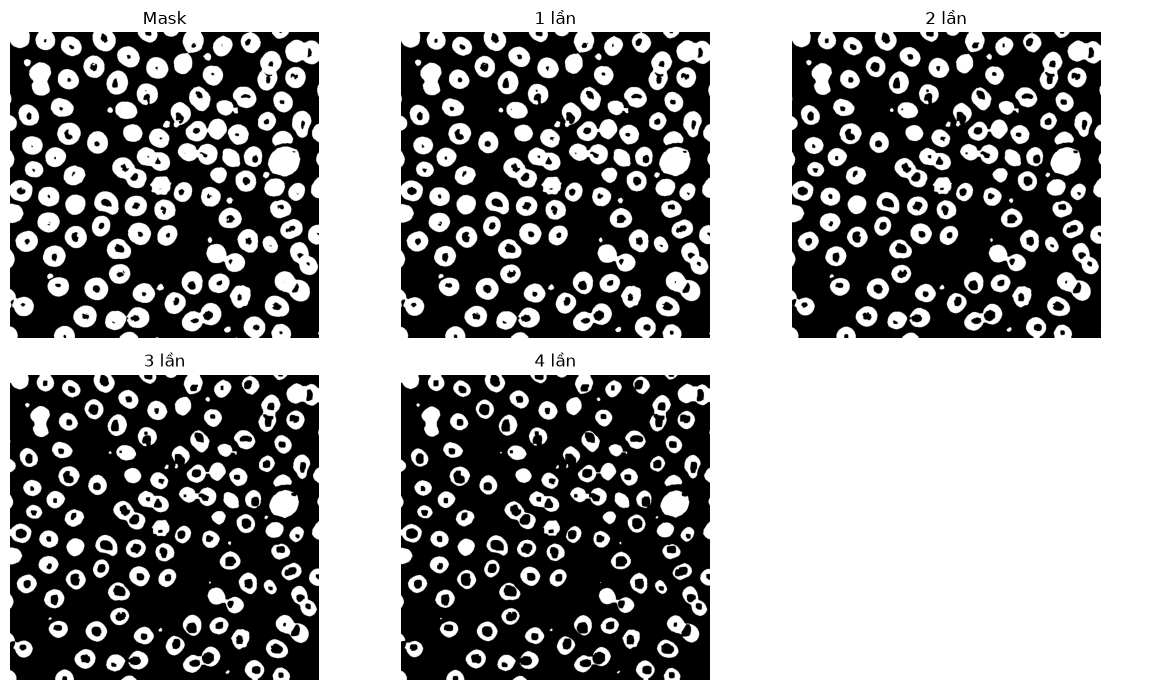

RBC3.jpg
  iterations=1: components=448, area=244175
  iterations=2: components=464, area=192688
  iterations=3: components=515, area=146382
  iterations=4: components=523, area=107731


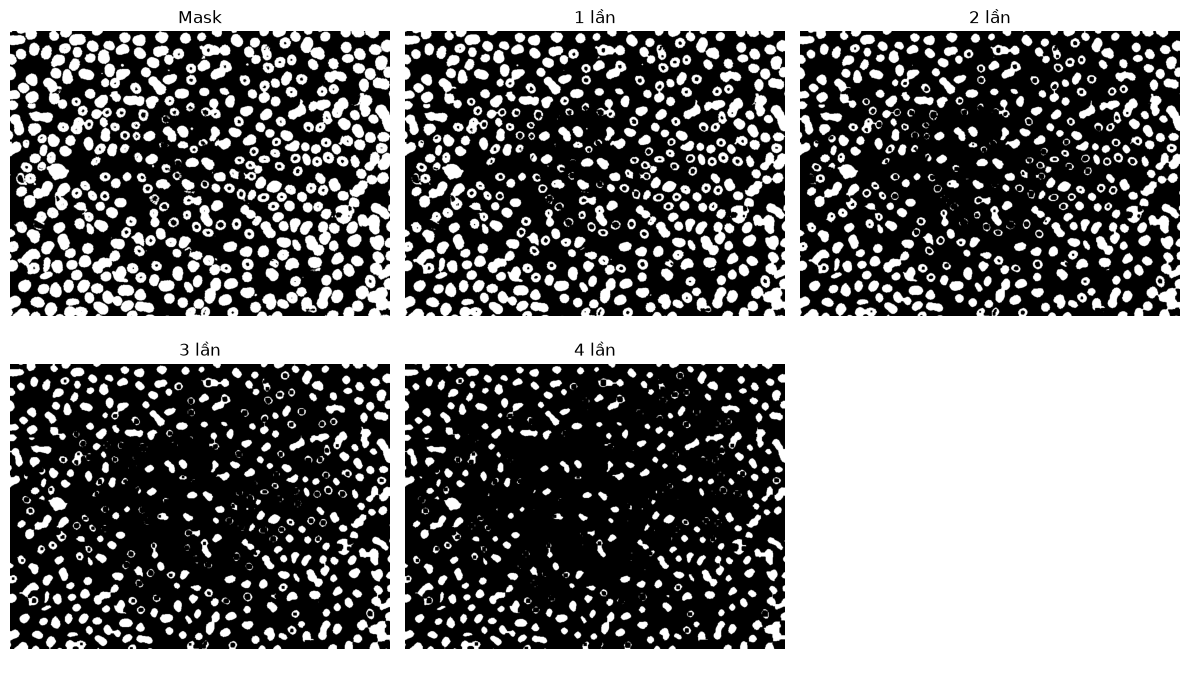

In [20]:
for name in ("RBC1.jpg", "RBC2.jpg", "RBC3.jpg"):
    gray = images[name]
    mask = make_binary(gray, invert=True)
    results = []
    print(name)
    for iterations in (1, 2, 3, 4):
        eroded = cv2.erode(mask, kernel3, iterations=iterations)
        results.append(eroded)
        print(
            f"  iterations={iterations}: "
            f"components={component_count(eroded)}, "
            f"area={foreground_area(eroded)}"
        )
    show_images([mask] + results, ["Mask", "1 lần", "2 lần", "3 lần", "4 lần"], cols=3)


### Nhận xét — tách vùng nối hẹp

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


## 5. Giãn (dilation) trên ảnh xám và ảnh nhị phân

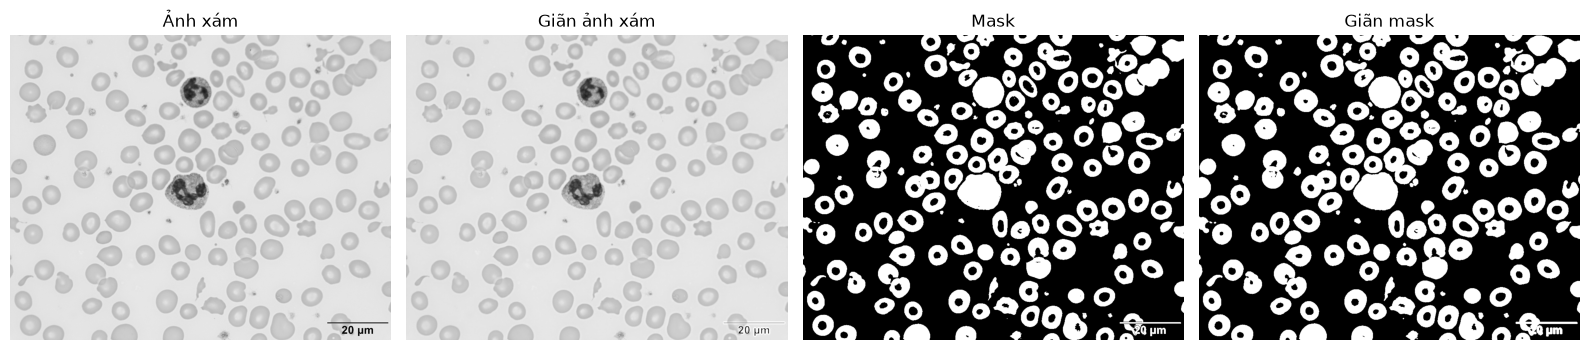

In [21]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
dilated_gray = cv2.dilate(image, kernel, iterations=1)
dilated_binary = cv2.dilate(binary, kernel, iterations=1)

show_images(
    [image, dilated_gray, binary, dilated_binary],
    ["Ảnh xám", "Giãn ảnh xám", "Mask", "Giãn mask"],
)


### Bài mở rộng Giãn 1 — nối khe và khe đứt

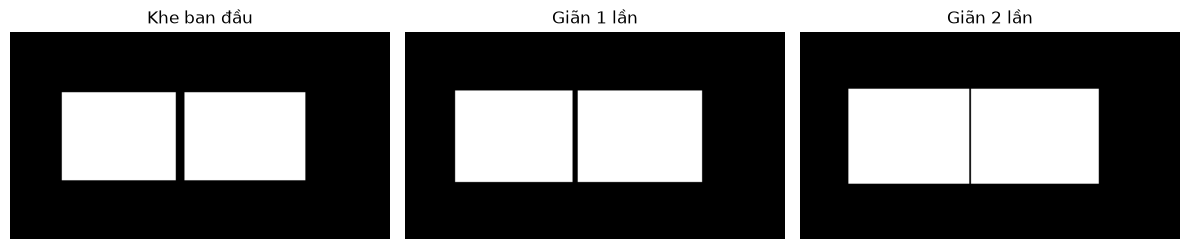

In [22]:
# Ảnh tổng hợp có hai phần trắng bị ngăn bởi một khe hẹp.
gap_mask = np.zeros((120, 220), dtype=np.uint8)
cv2.rectangle(gap_mask, (30, 35), (95, 85), 255, -1)
cv2.rectangle(gap_mask, (101, 35), (170, 85), 255, -1)

dilated_gap = cv2.dilate(gap_mask, kernel3, iterations=2)
show_images([gap_mask, cv2.dilate(gap_mask, kernel3, iterations=1), dilated_gap],
            ["Khe ban đầu", "Giãn 1 lần", "Giãn 2 lần"], cols=3)


### Nhận xét — khả năng nối vùng của dilation

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


### Bài mở rộng Giãn 2 — khi nào các vật thể bắt đầu dính?

In [23]:
for iterations in (1, 2, 3):
    result = cv2.dilate(gap_mask, kernel3, iterations=iterations)
    print(
        f"iterations={iterations}: "
        f"components={component_count(result)}, "
        f"area={foreground_area(result)}"
    )


iterations=1: components=2, area=7420
iterations=2: components=2, area=7920
iterations=3: components=1, area=8379


### Nhận xét — số lần giãn

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


### Bài mở rộng Giãn 3 — ảnh xám so với ảnh nhị phân

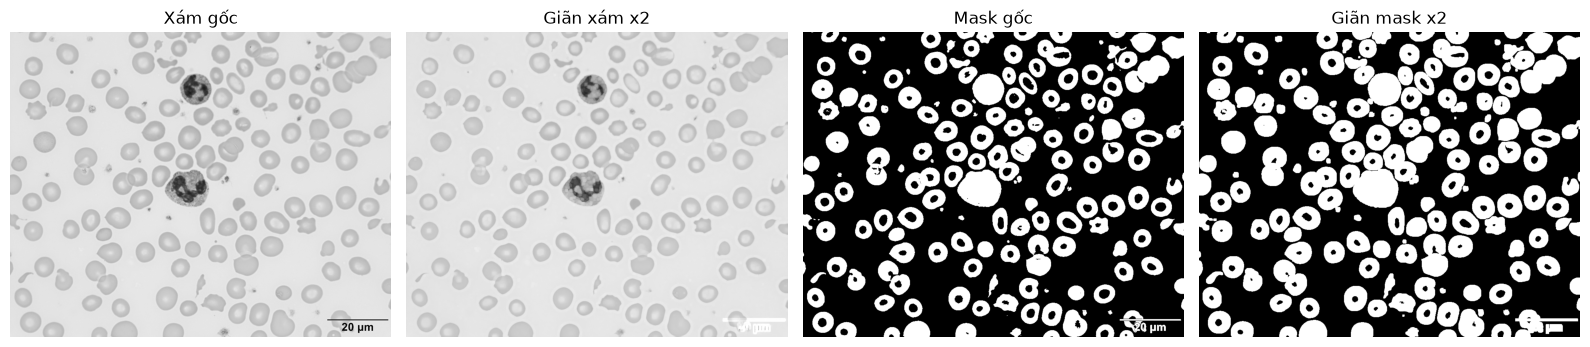

In [24]:
# Giãn ảnh xám giữ nhiều mức cường độ; giãn mask chỉ nở foreground trắng.
show_images(
    [image, cv2.dilate(image, kernel3, iterations=2),
     binary, cv2.dilate(binary, kernel3, iterations=2)],
    ["Xám gốc", "Giãn xám x2", "Mask gốc", "Giãn mask x2"],
)


### Nhận xét — kiểm soát hình dạng trên ảnh xám và nhị phân

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


## 6. Opening — co rồi giãn

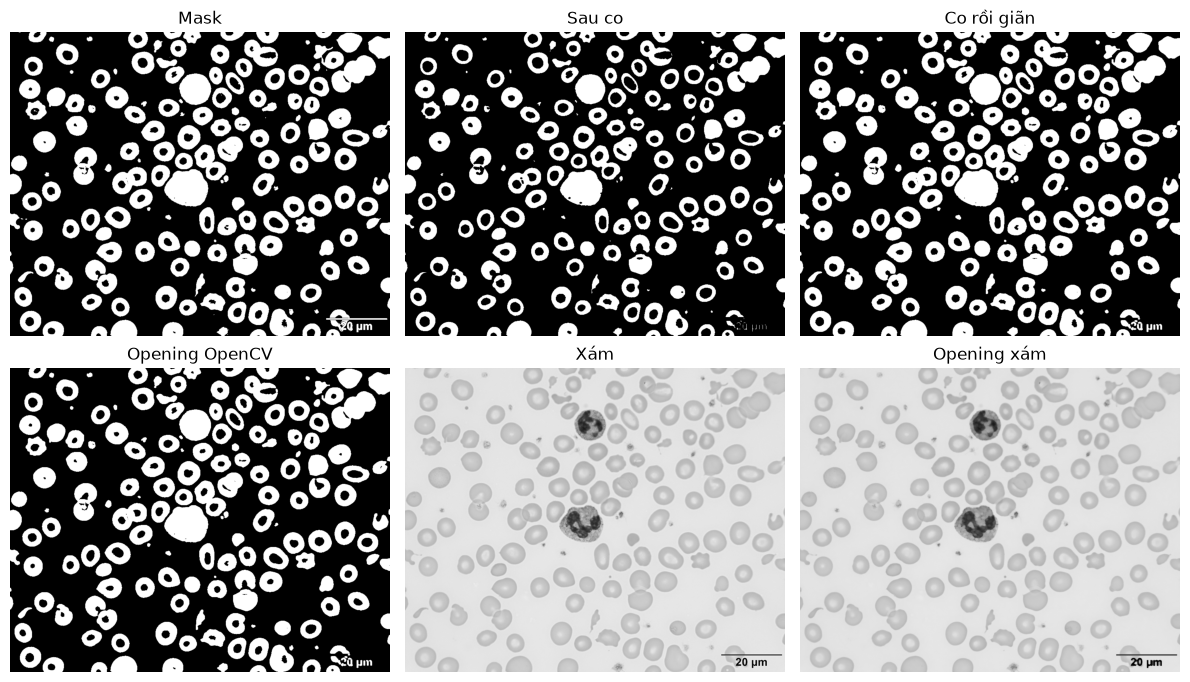

Manual và OpenCV giống nhau: True


In [25]:
kernel5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
temp_eroded = cv2.erode(binary, kernel5, iterations=1)
opened_manual = cv2.dilate(temp_eroded, kernel5, iterations=1)
opened_cv = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel5)
opened_gray = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel5)

show_images(
    [binary, temp_eroded, opened_manual, opened_cv, image, opened_gray],
    ["Mask", "Sau co", "Co rồi giãn", "Opening OpenCV", "Xám", "Opening xám"],
    cols=3,
)
print("Manual và OpenCV giống nhau:", np.array_equal(opened_manual, opened_cv))


### Bài mở rộng Opening 1 — kernel ellipse 3×3, 5×5, 7×7

3x3: area=250573, components=169
5x5: area=249225, components=170
7x7: area=247616, components=165


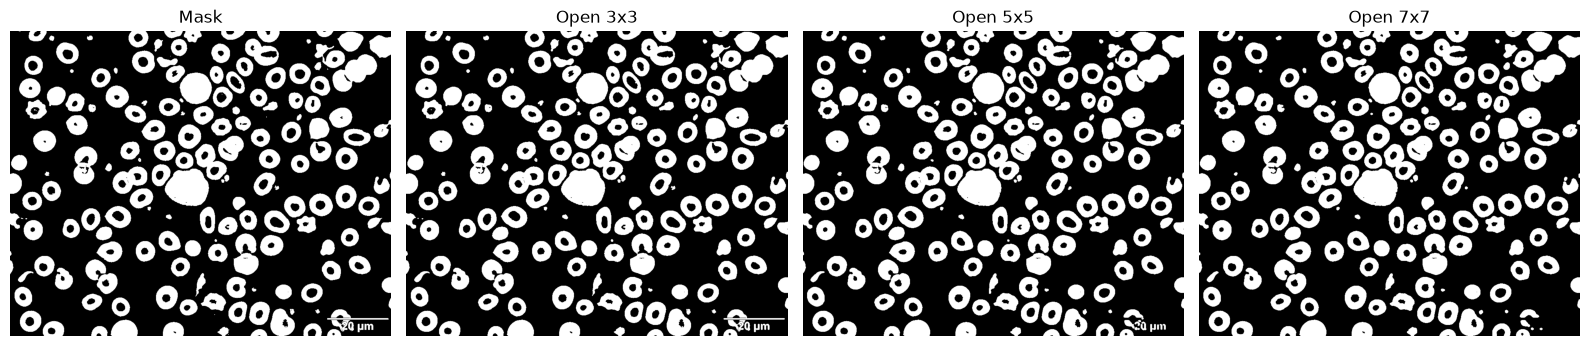

In [26]:
opening_results = []
for size in (3, 5, 7):
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    result = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
    opening_results.append(result)
    print(f"{size}x{size}: area={foreground_area(result)}, components={component_count(result)}")
show_images([binary] + opening_results, ["Mask", "Open 3x3", "Open 5x5", "Open 7x7"])


### Nhận xét — opening và erosion

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


### Bài mở rộng Opening 2 — so với co đơn thuần

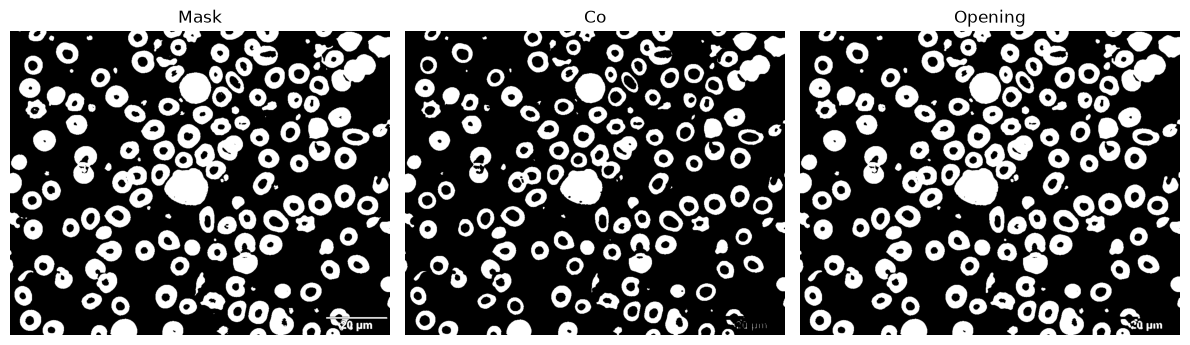

Area gốc: 250911
Area sau co: 190215
Area sau opening: 249225


In [27]:
eroded = cv2.erode(binary, kernel5, iterations=1)
opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel5)
show_images([binary, eroded, opened], ["Mask", "Co", "Opening"], cols=3)
print("Area gốc:", foreground_area(binary))
print("Area sau co:", foreground_area(eroded))
print("Area sau opening:", foreground_area(opened))


### Nhận xét — vì sao opening thường hiền hơn erosion

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


### Bài mở rộng Opening 3 — mất cấu trúc mảnh

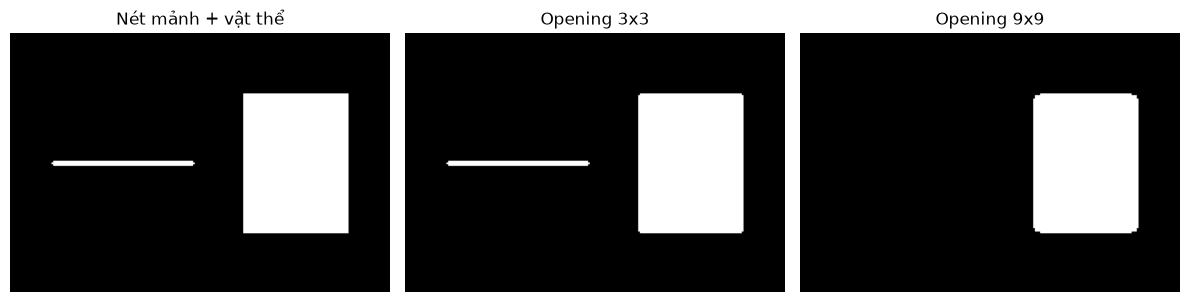

In [28]:
# Các nét trắng nhỏ và lớn để minh họa chi tiết bị loại khi kernel quá lớn.
thin_mask = np.zeros((150, 220), dtype=np.uint8)
cv2.line(thin_mask, (25, 75), (105, 75), 255, 2)
cv2.rectangle(thin_mask, (135, 35), (195, 115), 255, -1)
open_small = cv2.morphologyEx(thin_mask, cv2.MORPH_OPEN,
                               cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
open_large = cv2.morphologyEx(thin_mask, cv2.MORPH_OPEN,
                               cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
show_images([thin_mask, open_small, open_large],
            ["Nét mảnh + vật thể", "Opening 3x3", "Opening 9x9"], cols=3)


### Nhận xét — cấu trúc thật bị mất

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


## 7. Closing — giãn rồi co

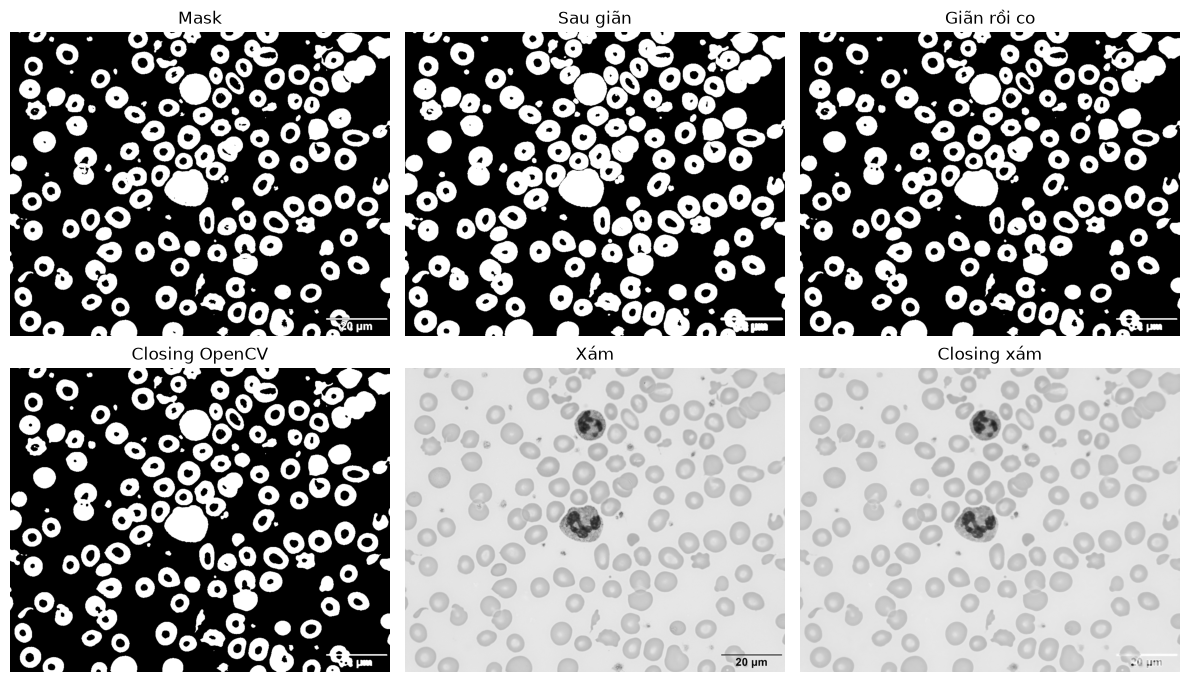

Manual và OpenCV giống nhau: True


In [29]:
temp_dilated = cv2.dilate(binary, kernel5, iterations=1)
closed_manual = cv2.erode(temp_dilated, kernel5, iterations=1)
closed_cv = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel5)
closed_gray = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel5)

show_images(
    [binary, temp_dilated, closed_manual, closed_cv, image, closed_gray],
    ["Mask", "Sau giãn", "Giãn rồi co", "Closing OpenCV", "Xám", "Closing xám"],
    cols=3,
)
print("Manual và OpenCV giống nhau:", np.array_equal(closed_manual, closed_cv))


### Bài mở rộng Closing 1 — lấp lỗ với kernel khác nhau

3x3: holes=2, area=10006
7x7: holes=2, area=10025
13x13: holes=1, area=10092


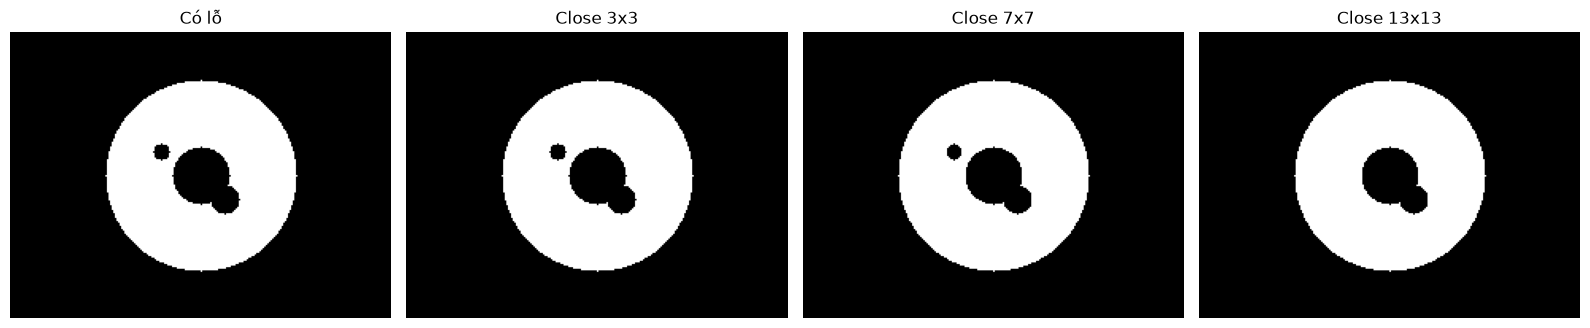

In [30]:
# Tạo vật thể trắng có một số lỗ đen nhỏ và một lỗ lớn hơn.
hole_mask = np.zeros((180, 240), dtype=np.uint8)
cv2.circle(hole_mask, (120, 90), 60, 255, -1)
cv2.circle(hole_mask, (95, 75), 5, 0, -1)
cv2.circle(hole_mask, (135, 105), 9, 0, -1)
cv2.circle(hole_mask, (120, 90), 18, 0, -1)

closing_results = []
for size in (3, 7, 13):
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    result = cv2.morphologyEx(hole_mask, cv2.MORPH_CLOSE, kernel)
    closing_results.append(result)
    print(f"{size}x{size}: holes={hole_count(result)}, area={foreground_area(result)}")
show_images([hole_mask] + closing_results,
            ["Có lỗ", "Close 3x3", "Close 7x7", "Close 13x13"])


### Nhận xét — kernel closing và lỗ nhỏ

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


### Bài mở rộng Closing 2 — closing và dilation

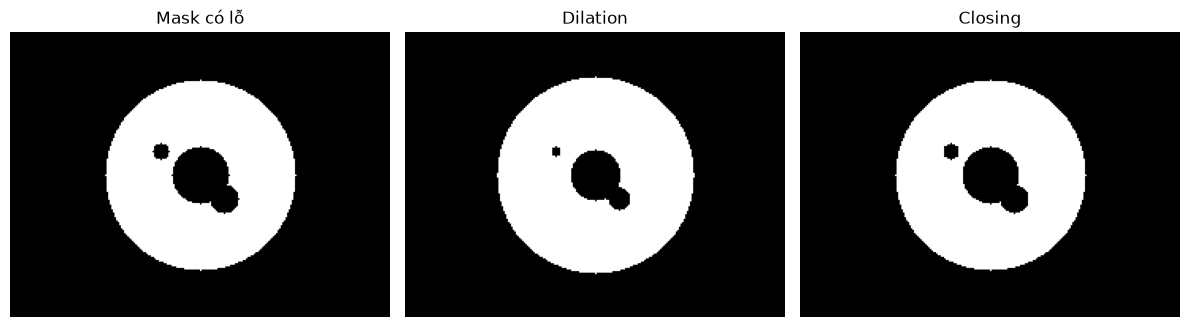

Lỗ ban đầu: 2
Lỗ sau dilation: 2
Lỗ sau closing: 2


In [31]:
dilated_holes = cv2.dilate(hole_mask, kernel5, iterations=1)
closed_holes = cv2.morphologyEx(hole_mask, cv2.MORPH_CLOSE, kernel5)
show_images([hole_mask, dilated_holes, closed_holes],
            ["Mask có lỗ", "Dilation", "Closing"], cols=3)
print("Lỗ ban đầu:", hole_count(hole_mask))
print("Lỗ sau dilation:", hole_count(dilated_holes))
print("Lỗ sau closing:", hole_count(closed_holes))


### Nhận xét — closing so với dilation

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


### Bài mở rộng Closing 3 — kernel vuông và ellipse trên vật thể gần tròn

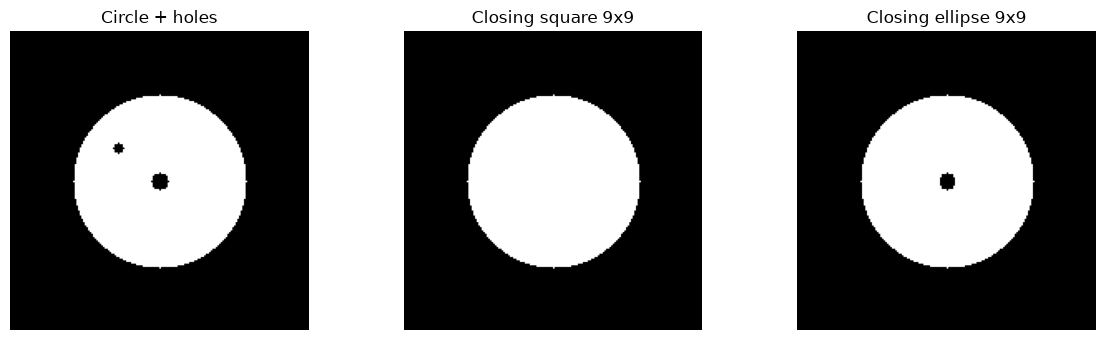

In [32]:
circle_mask = np.zeros((180, 180), dtype=np.uint8)
cv2.circle(circle_mask, (90, 90), 52, 255, -1)
cv2.circle(circle_mask, (90, 90), 5, 0, -1)
cv2.circle(circle_mask, (65, 70), 3, 0, -1)

closed_square = cv2.morphologyEx(circle_mask, cv2.MORPH_CLOSE,
    cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9)))
closed_ellipse = cv2.morphologyEx(circle_mask, cv2.MORPH_CLOSE,
    cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
show_images([circle_mask, closed_square, closed_ellipse],
            ["Circle + holes", "Closing square 9x9", "Closing ellipse 9x9"], cols=3)


### Nhận xét — kernel trên biên gần tròn

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


## 8. Quy trình ảnh xám → Otsu → opening → closing

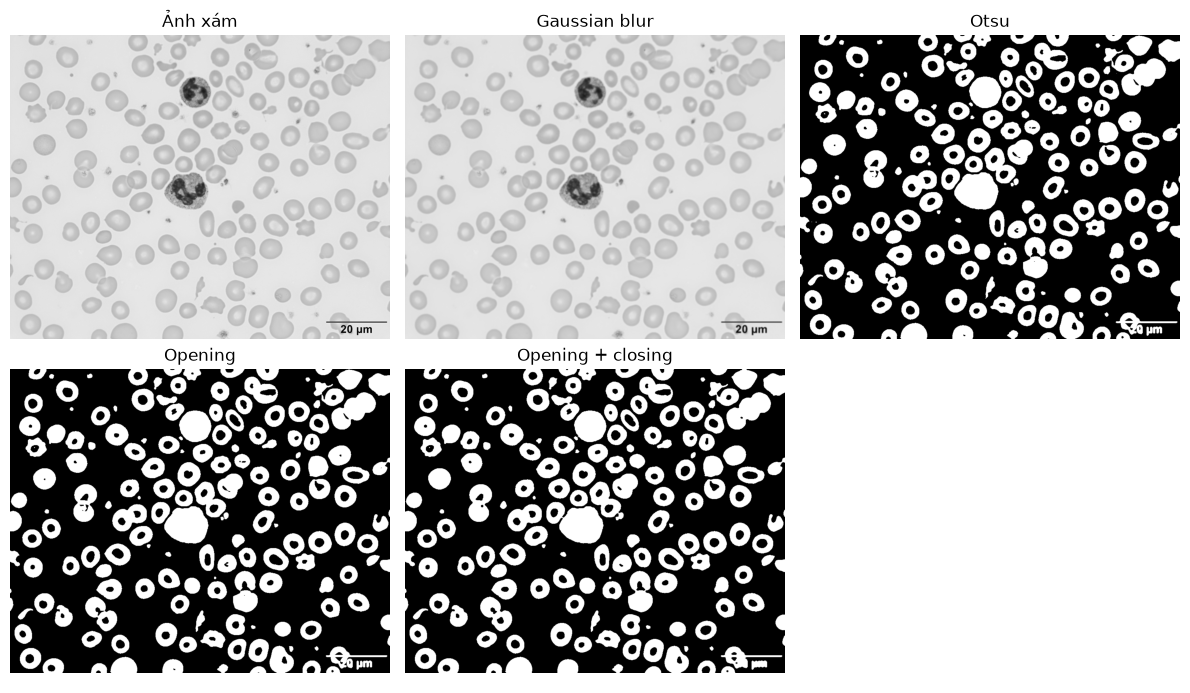

Components: 165 -> 156


In [33]:
# Một pipeline đơn giản: làm trơn nhẹ, ngưỡng hóa, bỏ chấm sáng, lấp lỗ.
blurred = cv2.GaussianBlur(image, (5, 5), 0)
_, pipeline_binary = cv2.threshold(
    blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)
kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
pipeline_open = cv2.morphologyEx(pipeline_binary, cv2.MORPH_OPEN, kernel_open)
pipeline_clean = cv2.morphologyEx(pipeline_open, cv2.MORPH_CLOSE, kernel_close)

show_images(
    [image, blurred, pipeline_binary, pipeline_open, pipeline_clean],
    ["Ảnh xám", "Gaussian blur", "Otsu", "Opening", "Opening + closing"],
    cols=3,
)
print("Components:", component_count(pipeline_binary), "->", component_count(pipeline_clean))


### Nhận xét — pipeline và thứ tự phép toán

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


## 9. So sánh Opening → Closing với Closing → Opening

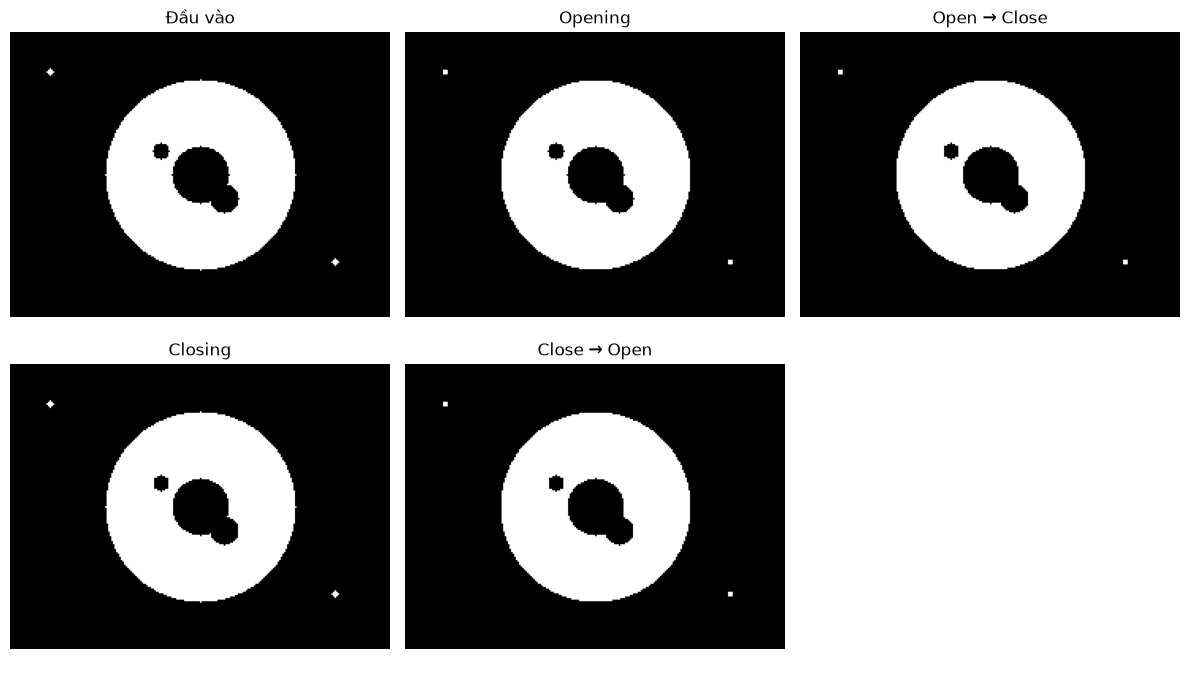

input area= 10032 components= 3 holes= 2
open-close area= 10032 components= 3 holes= 2
close-open area= 10033 components= 3 holes= 2


In [34]:
# Dùng mask có nhiễu sáng nhỏ và lỗ đen nhỏ để so thứ tự.
noisy_mask = hole_mask.copy()
cv2.circle(noisy_mask, (25, 25), 2, 255, -1)
cv2.circle(noisy_mask, (205, 145), 2, 255, -1)

open_first = cv2.morphologyEx(noisy_mask, cv2.MORPH_OPEN, kernel3)
open_then_close = cv2.morphologyEx(open_first, cv2.MORPH_CLOSE, kernel5)
close_first = cv2.morphologyEx(noisy_mask, cv2.MORPH_CLOSE, kernel5)
close_then_open = cv2.morphologyEx(close_first, cv2.MORPH_OPEN, kernel3)

show_images(
    [noisy_mask, open_first, open_then_close, close_first, close_then_open],
    ["Đầu vào", "Opening", "Open → Close", "Closing", "Close → Open"],
    cols=3,
)
for name, result in [("input", noisy_mask), ("open-close", open_then_close),
                     ("close-open", close_then_open)]:
    print(name, "area=", foreground_area(result),
          "components=", component_count(result), "holes=", hole_count(result))


### Nhận xét — so sánh thứ tự hai pipeline

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


## 10. Bài tập cuối bài 1 — làm sạch biên tế bào có gai

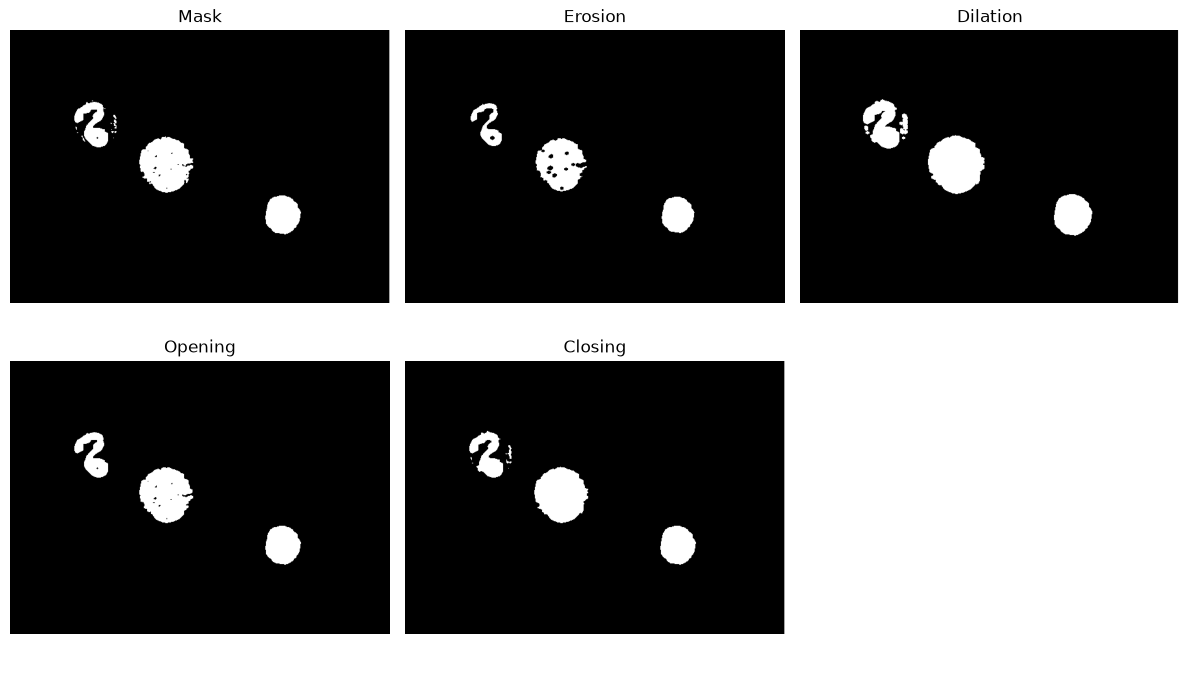

Mask area= 10100 components= 16
Erosion area= 7697 components= 3
Dilation area= 12966 components= 7
Opening area= 9491 components= 3
Closing area= 10290 components= 10


In [35]:
# Dùng một ảnh tế bào thật; nếu mask chưa đúng, đổi invert hoặc ảnh.
cell_gray = images["WBC1.jpg"]
cell_mask = make_binary(cell_gray, invert=True)
cell_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
cell_erosion = cv2.erode(cell_mask, cell_kernel, iterations=1)
cell_dilation = cv2.dilate(cell_mask, cell_kernel, iterations=1)
cell_opening = cv2.morphologyEx(cell_mask, cv2.MORPH_OPEN, cell_kernel)
cell_closing = cv2.morphologyEx(cell_mask, cv2.MORPH_CLOSE, cell_kernel)

cell_results = [cell_mask, cell_erosion, cell_dilation, cell_opening, cell_closing]
cell_titles = ["Mask", "Erosion", "Dilation", "Opening", "Closing"]
show_images(cell_results, cell_titles, cols=3)
for title, result in zip(cell_titles, cell_results):
    print(title, "area=", foreground_area(result),
          "components=", component_count(result))


### Nhận xét — chọn phép bỏ gai nhỏ

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


## 11. Bài tập cuối bài 2 — lấp lỗ nhỏ trong vùng tổn thương

kernel=3x3: holes=2, area=10006
kernel=7x7: holes=2, area=10025
kernel=13x13: holes=1, area=10092


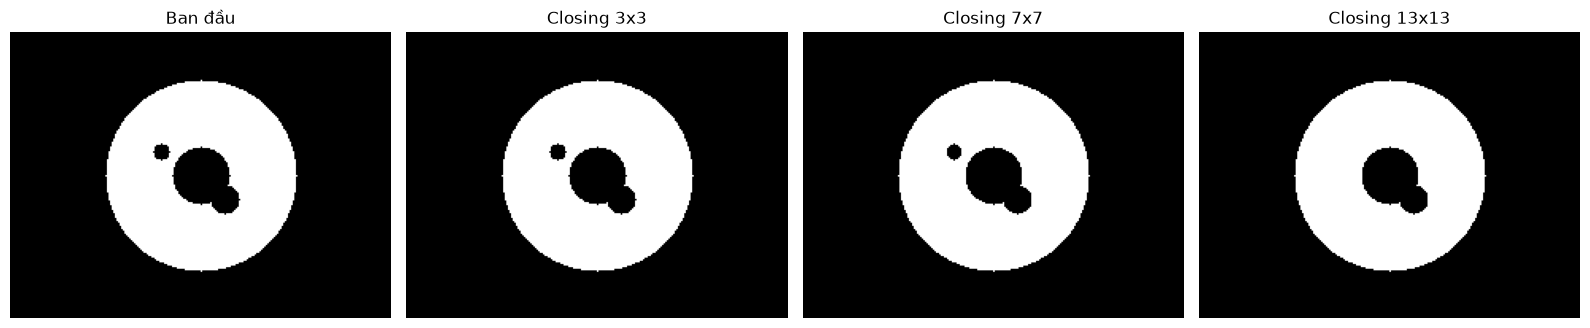

In [36]:
# So sánh ba kernel closing trên cùng mask có nhiều lỗ.
lesion_mask = hole_mask.copy()
lesion_closing = []
for size in (3, 7, 13):
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    result = cv2.morphologyEx(lesion_mask, cv2.MORPH_CLOSE, kernel)
    lesion_closing.append(result)
    print(f"kernel={size}x{size}: holes={hole_count(result)}, "
          f"area={foreground_area(result)}")
show_images([lesion_mask] + lesion_closing,
            ["Ban đầu", "Closing 3x3", "Closing 7x7", "Closing 13x13"])


### Nhận xét — lấp lỗ và biến dạng biên

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


## 12. Bài tập cuối bài 3 — so sánh hai chuỗi phép toán

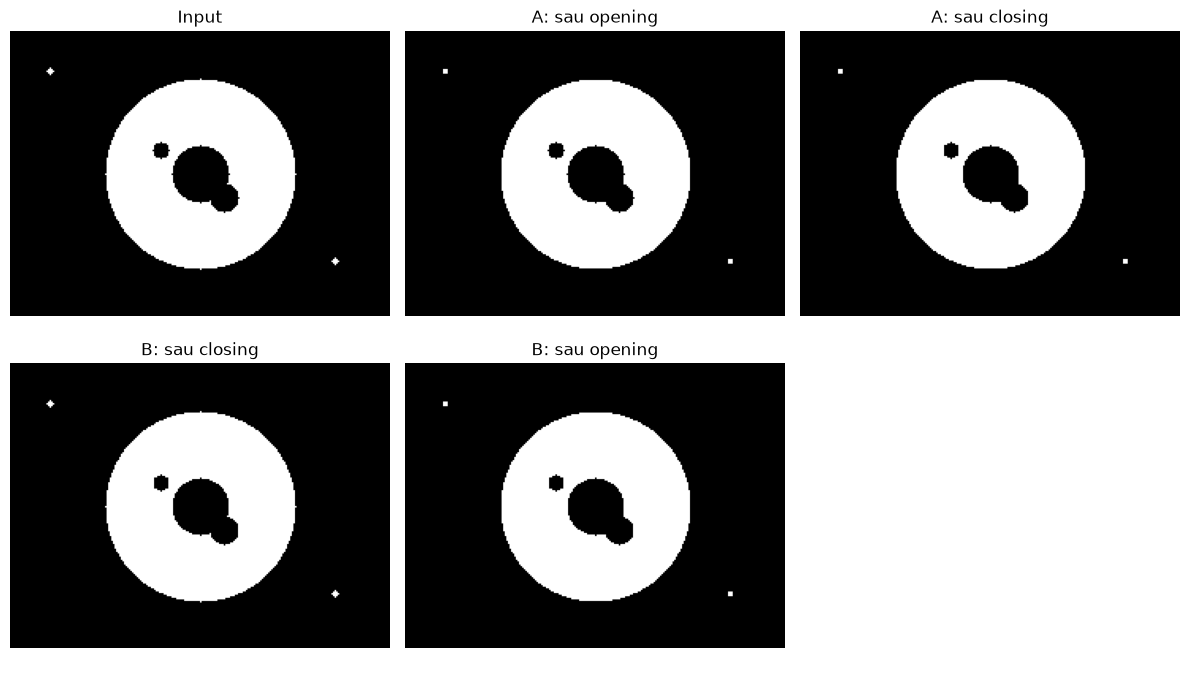

Input small components= 2 holes= 2 area= 10032
A Open→Close small components= 2 holes= 2 area= 10032
B Close→Open small components= 2 holes= 2 area= 10033


In [37]:
# Hiển thị từng bước để thấy thao tác nào loại/nối vùng trước.
step_open = cv2.morphologyEx(noisy_mask, cv2.MORPH_OPEN, kernel3)
step_open_close = cv2.morphologyEx(step_open, cv2.MORPH_CLOSE, kernel5)
step_close = cv2.morphologyEx(noisy_mask, cv2.MORPH_CLOSE, kernel5)
step_close_open = cv2.morphologyEx(step_close, cv2.MORPH_OPEN, kernel3)

show_images(
    [noisy_mask, step_open, step_open_close, step_close, step_close_open],
    ["Input", "A: sau opening", "A: sau closing",
     "B: sau closing", "B: sau opening"],
    cols=3,
)
for name, result in [("Input", noisy_mask), ("A Open→Close", step_open_close),
                     ("B Close→Open", step_close_open)]:
    print(name, "small components=",
          sum(1 for area in cv2.connectedComponentsWithStats(
              (result > 0).astype(np.uint8))[2][1:, cv2.CC_STAT_AREA] if area < 20),
          "holes=", hole_count(result), "area=", foreground_area(result))


### Nhận xét — hai thứ tự phép toán

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


## 13. Bài tập cuối bài 4 — tách hai tế bào dính bằng cầu hẹp

iterations=1: eroded components=1, restored components=1, restored area=14463
iterations=2: eroded components=1, restored components=1, restored area=14463
iterations=3: eroded components=1, restored components=1, restored area=14463


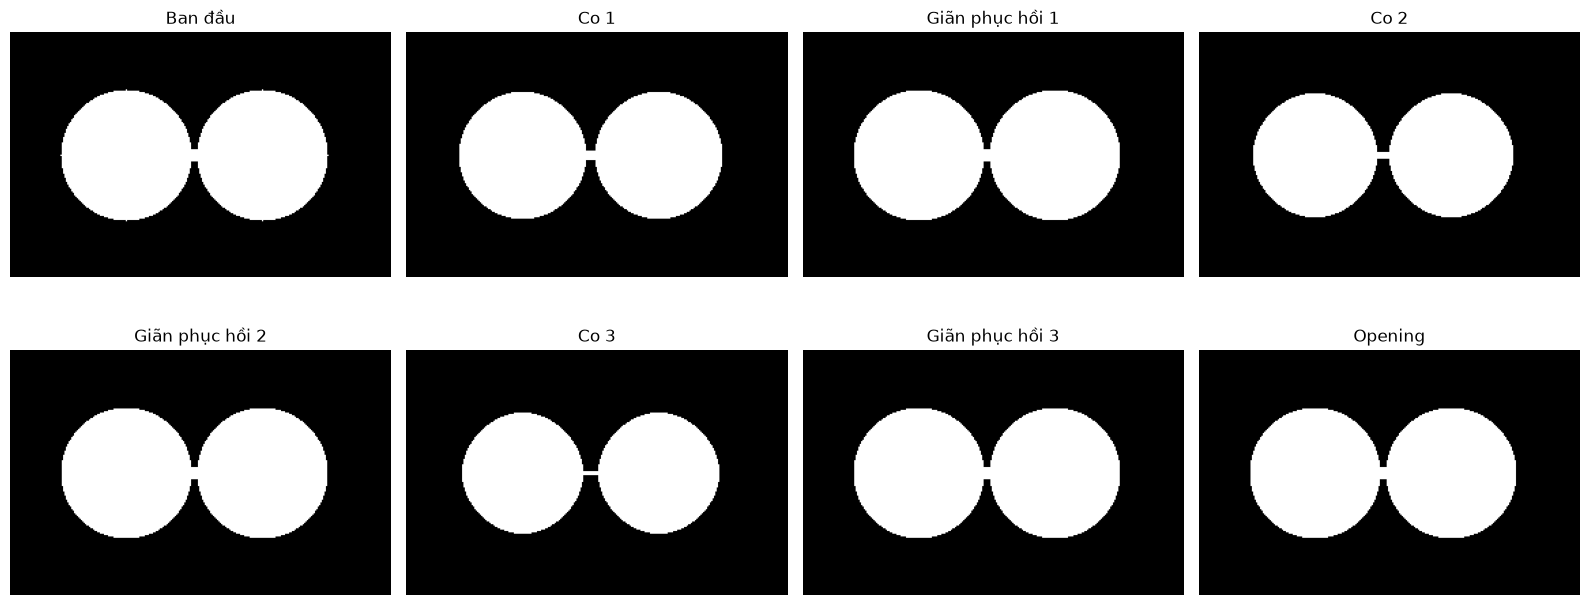

In [38]:
# Tạo hai tế bào tròn nối bằng một cầu mảnh để xem erosion có tách được không.
stuck_cells = np.zeros((180, 280), dtype=np.uint8)
cv2.circle(stuck_cells, (85, 90), 48, 255, -1)
cv2.circle(stuck_cells, (185, 90), 48, 255, -1)
cv2.rectangle(stuck_cells, (85, 86), (185, 94), 255, -1)

separation_results = []
for iterations in (1, 2, 3):
    eroded = cv2.erode(stuck_cells, kernel3, iterations=iterations)
    restored = cv2.dilate(eroded, kernel3, iterations=iterations)
    separation_results.append((eroded, restored))
    print(f"iterations={iterations}: eroded components={component_count(eroded)}, "
          f"restored components={component_count(restored)}, "
          f"restored area={foreground_area(restored)}")

opening_cells = cv2.morphologyEx(stuck_cells, cv2.MORPH_OPEN, kernel3)
show_images(
    [stuck_cells] + [result for pair in separation_results for result in pair] + [opening_cells],
    ["Ban đầu", "Co 1", "Giãn phục hồi 1", "Co 2", "Giãn phục hồi 2",
     "Co 3", "Giãn phục hồi 3", "Opening"],
    cols=4,
)


### Nhận xét — erosion phục hồi và opening

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


## 14. Bài tập cuối bài 5 — hình dạng kernel trên vật thể gần tròn

Vuông open area= 8383 close holes= 1
Ellipse open area= 8385 close holes= 1
Cross open area= 8387 close holes= 2


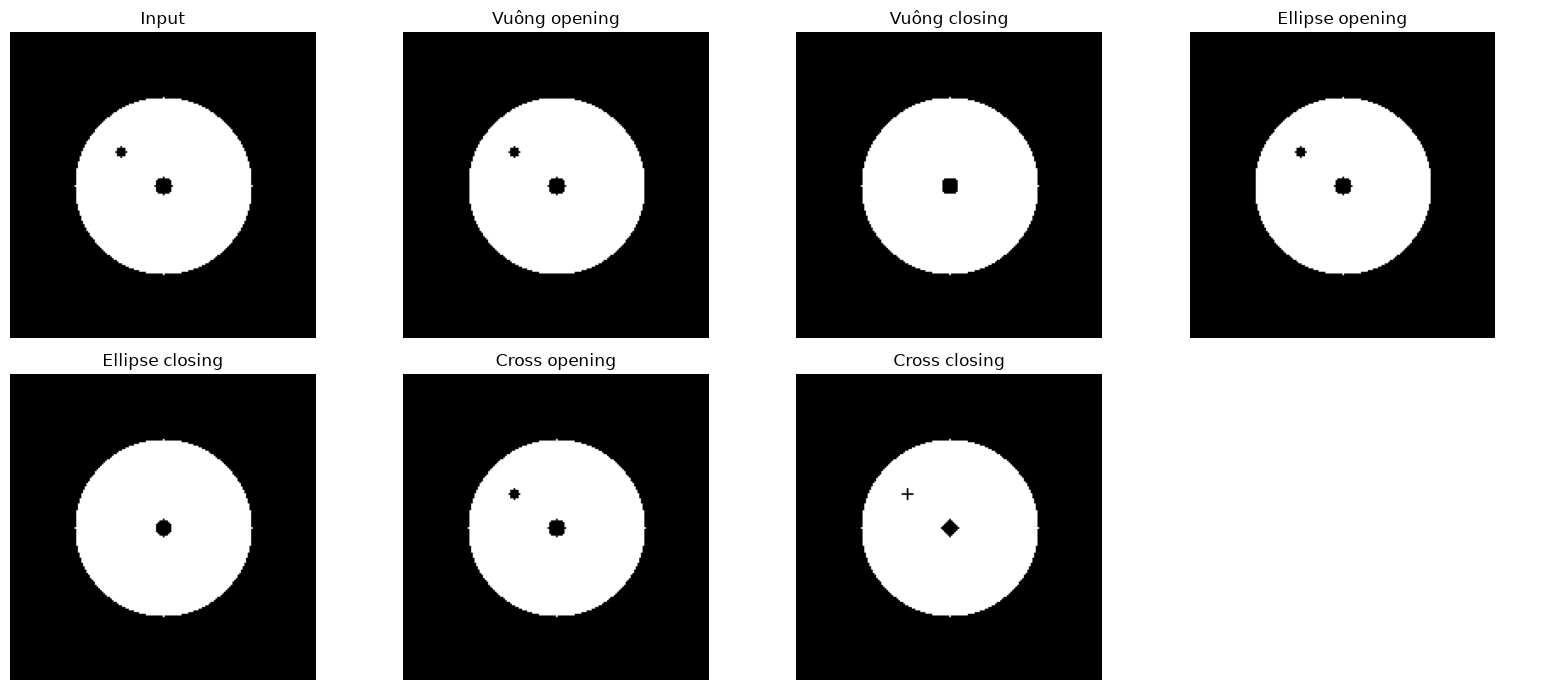

In [39]:
# Dùng vật thể tròn có lỗ và nhiễu nhỏ; thay kernel shape để so sánh.
shape_names = {
    "Vuông": cv2.MORPH_RECT,
    "Ellipse": cv2.MORPH_ELLIPSE,
    "Cross": cv2.MORPH_CROSS,
}
shape_results = []
shape_titles = []
for name, shape in shape_names.items():
    kernel = cv2.getStructuringElement(shape, (7, 7))
    opened = cv2.morphologyEx(circle_mask, cv2.MORPH_OPEN, kernel)
    closed = cv2.morphologyEx(circle_mask, cv2.MORPH_CLOSE, kernel)
    shape_results.extend([opened, closed])
    shape_titles.extend([f"{name} opening", f"{name} closing"])
    print(name, "open area=", foreground_area(opened),
          "close holes=", hole_count(closed))
show_images([circle_mask] + shape_results, ["Input"] + shape_titles, cols=4)


### Nhận xét — kernel vuông, ellipse và cross

<!-- Để trống theo yêu cầu: tự ghi nhận xét sau khi chạy cell. -->


## 15. Câu hỏi thảo luận — để tự trả lời sau khi chạy

1. Vì sao opening phù hợp để xóa chi tiết sáng nhỏ lồi ra ngoài, còn closing phù hợp để lấp lỗ tối nhỏ bên trong?

**Trả lời:**

2. Trong ảnh tế bào, khi nào làm mượt biên có thể gây hại cho phân tích y sinh?

**Trả lời:**

3. Vì sao cùng một phép toán trên ảnh xám và ảnh nhị phân cho cảm giác kết quả khác nhau?

**Trả lời:**

4. Nếu mục tiêu là đếm tế bào, chọn pipeline nào để làm sạch nhiễu nhưng hạn chế hai tế bào nhập vào nhau?

**Trả lời:**

5. Khi nào tăng kích thước kernel, khi nào giữ kernel nhỏ nhưng tăng số lần lặp?

**Trả lời:**


## Gợi ý kiểm tra trước khi viết nhận xét

- Mask đang để tế bào trắng hay nền trắng?
- So sánh trên cùng một ảnh và giữ các tham số khác như nhau.
- Co/giãn ảnh xám lấy cực tiểu/cực đại cục bộ; trên mask nhị phân chúng trực tiếp thay đổi hình dạng foreground.
- Opening = co rồi giãn; closing = giãn rồi co. Nếu cùng kernel và số lần lặp, chuỗi thủ công nên khớp với phép OpenCV tương ứng.
- Kernel lớn hoặc nhiều iterations có thể xóa chi tiết thật, lấp khe giữa hai tế bào hoặc làm thay đổi diện tích.
